# HAM10000 — Data-Quality Investigation

**Project:** Group capstone, Module B: AI for Leaders — topic: *early cancer detection*.

**Dataset:** HAM10000 ("Human Against Machine with 10000 training images"), Tschandl, Rosendahl & Kittler (2018), *Scientific Data* 5, 180161.
Source: Harvard Dataverse, https://doi.org/10.7910/DVN/DBW86T. It contains dermatoscopic (skin-microscope) images of pigmented skin
lesions, plus a metadata table with one row per image.

**Purpose of this notebook:** describe what is in the dataset, which data types it uses, how clean it is, and what that means for
machine learning. Every number below is computed from the **complete** dataset, so the Milestone Two paper can rely on it.
At the end, the results are compared with published reference values and exported to `outputs/`.

This notebook only *investigates* the data: no modeling, no imputation, and no rows are deleted. The raw files in `data/` are never modified.

## 0. Setup
Imports, file paths and library versions. All outputs (tables, figures, facts file) go to `outputs/`.

In [1]:
import hashlib
import io
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from PIL import Image
from IPython.display import Markdown, display

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
    SEABORN = sns.__version__
except ImportError:
    SEABORN = "not installed"

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"
IMAGE_DIRS = [DATA_DIR / "HAM10000_images_part_1", DATA_DIR / "HAM10000_images_part_2"]
OUT_DIR = PROJECT_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Stop early (instead of inventing data) if the metadata file is missing.
if not METADATA_PATH.exists():
    raise FileNotFoundError(f"Metadata file not found: {METADATA_PATH}")

IMAGES_AVAILABLE = all(d.is_dir() for d in IMAGE_DIRS)

print("Python    ", platform.python_version())
print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn   ", SEABORN)
print("Pillow    ", PIL.__version__)
print()
print("Metadata  ", METADATA_PATH.relative_to(PROJECT_DIR))
for d in IMAGE_DIRS:
    print("Image dir ", d.relative_to(PROJECT_DIR), "->", "found" if d.is_dir() else "MISSING")
print("Images available:", IMAGES_AVAILABLE)

Python     3.13.7
pandas     3.1.1
numpy      2.5.4
matplotlib 3.11.2
seaborn    0.13.2
Pillow     13.0.0

Metadata   data/HAM10000_metadata.csv
Image dir  data/HAM10000_images_part_1 -> found
Image dir  data/HAM10000_images_part_2 -> found
Images available: True


### Helper functions
Small helpers used throughout:
- `pct` / `fmt_n` / `fmt_pct` — consistent number formatting (thousands separators, one decimal place for %).
- `fact` — stores a labelled number for the final facts file, grouped by section.
- `count_table` — counts and percentages for one column.
- `missing_summary` — blank cells **and** hidden-missing values (e.g. the text "unknown") per column.
- `save_fig` — saves the current figure as PNG in `outputs/figures/`.

In [2]:
def pct(part, whole):
    return 100.0 * part / whole if whole else float("nan")

def fmt_n(n):
    return f"{int(n):,}"

def fmt_pct(p):
    return f"{p:.1f}%"

FACTS = {}  # section -> list of "Label: value" strings

def fact(section, label, value):
    FACTS.setdefault(section, []).append(f"{label}: {value}")

def count_table(series, name=None, labels=None):
    counts = series.value_counts(dropna=False)
    out = pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(1)})
    out.index.name = name or series.name
    if labels is not None:
        out.insert(0, "full name", [labels.get(k, "") for k in out.index])
    return out

HIDDEN_MISSING_TOKENS = {"unknown", "", "nan", "none", "null", "n/a", "na", "?"}

def missing_summary(frame):
    """Per column: blank cells (NaN), empty/whitespace-only strings, and placeholder text such as 'unknown'."""
    rows = []
    for col in frame.columns:
        s = frame[col]
        blank = int(s.isna().sum())
        if s.dtype == object or pd.api.types.is_string_dtype(s):
            text = s.dropna().astype(str)
            empty = int((text.str.strip() == "").sum())
            placeholder = int(text.str.strip().str.lower().isin(HIDDEN_MISSING_TOKENS - {""}).sum())
        else:
            empty = placeholder = 0
        rows.append({"column": col, "dtype": str(s.dtype), "blank (NaN)": blank,
                     "blank %": round(pct(blank, len(frame)), 2), "empty strings": empty,
                     "placeholder ('unknown' etc.)": placeholder,
                     "placeholder %": round(pct(placeholder, len(frame)), 2)})
    return pd.DataFrame(rows).set_index("column")

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved", path.relative_to(PROJECT_DIR))

## 1. Basic structure
First we load the metadata table and look at its shape, the data type of each column and the first rows.
This tells us what one row represents (one image) and which columns are numbers versus text categories.

In [3]:
meta = pd.read_csv(METADATA_PATH)
n_rows, n_cols = meta.shape
print(f"Rows: {n_rows:,}   Columns: {n_cols}")
print("Columns:", list(meta.columns))
EXPECTED_COLS = ["lesion_id", "image_id", "dx", "dx_type", "age", "sex", "localization"]
extra_cols = [c for c in meta.columns if c not in EXPECTED_COLS]
missing_cols = [c for c in EXPECTED_COLS if c not in meta.columns]
print("Columns beyond the 7 documented ones:", extra_cols or "none")
print("Documented columns that are missing:", missing_cols or "none")

fact("Structure", "Images (metadata rows)", fmt_n(n_rows))
fact("Structure", "Metadata columns", f"{n_cols} ({', '.join(meta.columns)})")
if extra_cols:
    fact("Structure", "Extra column(s) not in the 7 documented ones", ", ".join(extra_cols))

Rows: 10,015   Columns: 8
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']
Columns beyond the 7 documented ones: ['dataset']
Documented columns that are missing: none


In [4]:
dtype_table = pd.DataFrame({
    "pandas dtype": meta.dtypes.astype(str),
    "unique values": meta.nunique(dropna=True),
    "example": meta.iloc[0],
})
KIND = {"lesion_id": "identifier (text)", "image_id": "identifier (text)", "dx": "categorical (label)",
        "dx_type": "categorical", "age": "numeric (years)", "sex": "categorical", "localization": "categorical"}
dtype_table["kind"] = [KIND.get(c, "categorical") for c in meta.columns]
dtype_table

,pandas dtype,unique values,example,kind
lesion_id,str,7470,HAM_0000118,identifier (text)
image_id,str,10015,ISIC_0027419,identifier (text)
dx,str,7,bkl,categorical (label)
dx_type,str,4,histo,categorical
age,float64,18,80.0,numeric (years)
sex,str,3,male,categorical
localization,str,15,scalp,categorical
dataset,str,4,vidir_modern,categorical


In [5]:
meta.head(10)

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern
5,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,vidir_modern
6,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face,vidir_modern
7,HAM_0002761,ISIC_0029068,bkl,histo,60.0,male,face,vidir_modern
8,HAM_0005132,ISIC_0025837,bkl,histo,70.0,female,back,vidir_modern
9,HAM_0005132,ISIC_0025209,bkl,histo,70.0,female,back,vidir_modern


### Blank and hidden-missing values
A cell can be missing in two ways:
1. **Blank** — the cell is empty (pandas shows `NaN`).
2. **Hidden missing** — the cell has a value, but the value means "we don't know", e.g. the word `unknown`, an empty string,
   or an impossible age (below 0 or above 120). These are easy to miss because a simple blank count does not see them.

In [6]:
miss = missing_summary(meta)
display(miss)

total_cells = meta.size
total_blank = int(meta.isna().sum().sum())
print(f"Total cells: {total_cells:,}")
print(f"Total blank cells: {total_blank:,} ({fmt_pct(pct(total_blank, total_cells))})")
print(f"Rows with at least one blank cell: {int(meta.isna().any(axis=1).sum()):,}")

fact("Structure", "Total cells", fmt_n(total_cells))
fact("Structure", "Blank cells (total)", f"{fmt_n(total_blank)} ({pct(total_blank, total_cells):.2f}% of all cells)")
for col, n in meta.isna().sum().items():
    if n:
        fact("Structure", f"Blank cells in {col}", f"{fmt_n(n)} images ({fmt_pct(pct(n, n_rows))})")

,dtype,blank (NaN),blank %,empty strings,placeholder ('unknown' etc.),placeholder %
column,,,,,,
lesion_id,str,0,0.00,0,0,0.00
image_id,str,0,0.00,0,0,0.00
dx,str,0,0.00,0,0,0.00
dx_type,str,0,0.00,0,0,0.00
age,float64,57,0.57,0,0,0.00
sex,str,0,0.00,0,57,0.57
localization,str,0,0.00,0,234,2.34
dataset,str,0,0.00,0,0,0.00


Total cells: 80,120
Total blank cells: 57 (0.1%)
Rows with at least one blank cell: 57


In [7]:
age_blank = int(meta["age"].isna().sum())
sex_unknown = int((meta["sex"].str.lower() == "unknown").sum())
loc_unknown = int((meta["localization"].str.lower() == "unknown").sum())
empty_strings = int(miss["empty strings"].sum())
impossible_age = int(((meta["age"] < 0) | (meta["age"] > 120)).sum())
age_zero = int((meta["age"] == 0).sum())

hidden = pd.DataFrame({
    "check": ["age blank (NaN)", "sex = 'unknown'", "localization = 'unknown'",
              "empty strings (any column)", "impossible age (<0 or >120)", "age = 0 (possible placeholder)"],
    "images": [age_blank, sex_unknown, loc_unknown, empty_strings, impossible_age, age_zero],
})
hidden["percent"] = (100 * hidden["images"] / n_rows).round(1)
display(hidden)

any_unknown = meta["age"].isna() | meta["sex"].eq("unknown") | meta["localization"].eq("unknown")
hidden_missing_cells = sex_unknown + loc_unknown + empty_strings + impossible_age
print(f"Hidden-missing cells ('unknown' + empty strings + impossible ages): {hidden_missing_cells:,}")
print(f"Images with at least one unknown (blank age, unknown sex or unknown localization): {int(any_unknown.sum()):,}"
      f" ({fmt_pct(pct(any_unknown.sum(), n_rows))})")

# How do the unknowns overlap?
overlap = pd.crosstab(meta["age"].isna().rename("age blank"), meta["sex"].eq("unknown").rename("sex unknown"))
display(overlap)

fact("Structure", "Age missing (blank)", f"{fmt_n(age_blank)} images ({fmt_pct(pct(age_blank, n_rows))})")
fact("Structure", "Sex 'unknown'", f"{fmt_n(sex_unknown)} images ({fmt_pct(pct(sex_unknown, n_rows))})")
fact("Structure", "Localization 'unknown'", f"{fmt_n(loc_unknown)} images ({fmt_pct(pct(loc_unknown, n_rows))})")
fact("Structure", "Empty strings", fmt_n(empty_strings))
fact("Structure", "Impossible ages (<0 or >120)", fmt_n(impossible_age))
fact("Structure", "Age recorded as 0", f"{fmt_n(age_zero)} images")
fact("Structure", "Hidden-missing cells (unknown/empty/impossible)", fmt_n(hidden_missing_cells))
fact("Structure", "Images with at least one unknown (age, sex or localization)",
     f"{fmt_n(any_unknown.sum())} ({fmt_pct(pct(any_unknown.sum(), n_rows))})")

,check,images,percent
0,age blank (NaN),57,0.6
1,sex = 'unknown',57,0.6
2,localization = 'unknown',234,2.3
3,empty strings (any column),0,0.0
4,impossible age (<0 or >120),0,0.0
5,age = 0 (possible placeholder),39,0.4


Hidden-missing cells ('unknown' + empty strings + impossible ages): 291
Images with at least one unknown (blank age, unknown sex or unknown localization): 254 (2.5%)


sex unknown,False,True
age blank,,
False,9948,10
True,10,47


### Duplicates
Exact duplicate rows would double-count an image. Each `image_id` should appear only once, because each row describes one image file.

In [8]:
dup_rows = int(meta.duplicated().sum())
dup_image_ids = int(meta["image_id"].duplicated().sum())
print(f"Exact duplicate rows: {dup_rows:,}")
print(f"Duplicate image_ids: {dup_image_ids:,}")
fact("Structure", "Exact duplicate rows", fmt_n(dup_rows))
fact("Structure", "Duplicate image_ids", fmt_n(dup_image_ids))

Exact duplicate rows: 0
Duplicate image_ids: 0


## 2. Labels
The column `dx` is the diagnosis — the label a model would learn to predict. We count each of the 7 classes, compute the share of
**malignant** (cancerous) lesions, and check *how* each diagnosis was confirmed (`dx_type`). Histopathology (`histo`, a lab
examination of removed tissue) is the strongest form of ground truth; `follow_up`, `consensus` and `confocal` are weaker.

In [9]:
DX_NAMES = {
    "akiec": "Actinic keratosis / Bowen's disease",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevus",
    "vasc": "Vascular lesion",
}
MALIGNANT = ["mel", "bcc", "akiec"]

dx_table = count_table(meta["dx"], "dx", DX_NAMES)
dx_table["malignant"] = dx_table.index.isin(MALIGNANT)
display(dx_table)

for code_, row in dx_table.iterrows():
    fact("Labels", f"{row['full name']} ({code_})", f"{fmt_n(row['count'])} images ({fmt_pct(row['percent'])})")

imbalance_ratio = dx_table["count"].max() / dx_table["count"].min()
print(f"Largest / smallest class: {imbalance_ratio:.1f} : 1")
fact("Labels", "Imbalance ratio largest/smallest class (nv/df)", f"{imbalance_ratio:.1f} : 1")

,full name,count,percent,malignant
dx,,,,
nv,Melanocytic nevus,6705,66.9,False
mel,Melanoma,1113,11.1,True
bkl,Benign keratosis,1099,11.0,False
bcc,Basal cell carcinoma,514,5.1,True
akiec,Actinic keratosis / Bowen's disease,327,3.3,True
vasc,Vascular lesion,142,1.4,False
df,Dermatofibroma,115,1.1,False


Largest / smallest class: 58.3 : 1


In [10]:
meta["malignant"] = meta["dx"].isin(MALIGNANT)
n_malig = int(meta["malignant"].sum())
malig_pct = pct(n_malig, n_rows)
malig_table = pd.DataFrame({
    "count": [n_malig, n_rows - n_malig],
    "percent": [round(malig_pct, 1), round(100 - malig_pct, 1)],
}, index=["malignant (mel + bcc + akiec)", "benign (nv + bkl + df + vasc)"])
display(malig_table)
fact("Labels", "Malignant (mel + bcc + akiec)", f"{fmt_n(n_malig)} images ({fmt_pct(malig_pct)})")
fact("Labels", "Benign (nv + bkl + df + vasc)", f"{fmt_n(n_rows - n_malig)} images ({fmt_pct(100 - malig_pct)})")

,count,percent
malignant (mel + bcc + akiec),1954,19.5
benign (nv + bkl + df + vasc),8061,80.5


In [11]:
DXTYPE_NAMES = {
    "histo": "Histopathology",
    "follow_up": "Follow-up examination",
    "consensus": "Expert consensus",
    "confocal": "Confocal microscopy",
}
dxtype_table = count_table(meta["dx_type"], "dx_type", DXTYPE_NAMES)
display(dxtype_table)
for code_, row in dxtype_table.iterrows():
    fact("Labels", f"Confirmed by {row['full name'].lower()} ({code_})", f"{fmt_n(row['count'])} images ({fmt_pct(row['percent'])})")

,full name,count,percent
dx_type,,,
histo,Histopathology,5340,53.3
follow_up,Follow-up examination,3704,37.0
consensus,Expert consensus,902,9.0
confocal,Confocal microscopy,69,0.7


### Diagnosis × confirmation method
Which diagnoses were confirmed in which way? If one class is confirmed mostly by a weaker method, its labels are less certain.

In [12]:
ct = pd.crosstab(meta["dx"], meta["dx_type"], margins=True, margins_name="total")
display(ct)
ct_pct = (pd.crosstab(meta["dx"], meta["dx_type"], normalize="index") * 100).round(1)
print("Row percentages (share of each dx confirmed by each method):")
display(ct_pct)

histo_malig = pct(meta.loc[meta["malignant"], "dx_type"].eq("histo").sum(), n_malig)
fact("Labels", "Malignant images confirmed by histopathology", fmt_pct(histo_malig))
fu_only = ct_pct.loc[:, "follow_up"]
fact("Labels", "Classes with any follow_up confirmation",
     ", ".join(f"{k} ({fmt_pct(v)})" for k, v in fu_only[fu_only > 0].items()))

dx_type,confocal,consensus,follow_up,histo,total
dx,,,,,
akiec,0,0,0,327,327
bcc,0,0,0,514,514
bkl,69,264,0,766,1099
df,0,60,0,55,115
mel,0,0,0,1113,1113
nv,0,503,3704,2498,6705
vasc,0,75,0,67,142
total,69,902,3704,5340,10015


Row percentages (share of each dx confirmed by each method):


dx_type,confocal,consensus,follow_up,histo
dx,,,,
akiec,0.0,0.0,0.0,100.0
bcc,0.0,0.0,0.0,100.0
bkl,6.3,24.0,0.0,69.7
df,0.0,52.2,0.0,47.8
mel,0.0,0.0,0.0,100.0
nv,0.0,7.5,55.2,37.3
vasc,0.0,52.8,0.0,47.2


### Class balance chart

Saved outputs/figures/01_class_balance.png


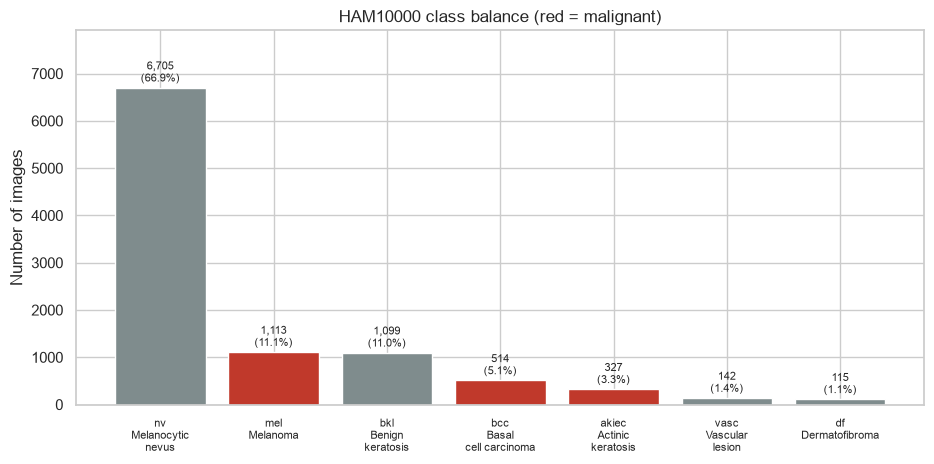

In [13]:
order = dx_table.sort_values("count", ascending=False)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = ["#c0392b" if m else "#7f8c8d" for m in order["malignant"]]
bars = ax.bar([f"{k}\n" + DX_NAMES[k].split(' /')[0].replace(' ', '\n', 1) for k in order.index], order["count"], color=colors)
for b, (c, p) in zip(bars, zip(order["count"], order["percent"])):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 60, f"{c:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Number of images")
ax.set_title("HAM10000 class balance (red = malignant)")
ax.set_ylim(0, order["count"].max() * 1.18)
plt.setp(ax.get_xticklabels(), fontsize=8)
fig.tight_layout()
save_fig(fig, "01_class_balance")
plt.show()

## 3. Lesions vs. images
One skin lesion (one mole or spot, `lesion_id`) can have several images (`image_id`) — e.g. photographed at different times or
magnifications. Here we count unique lesions, how many images each has, and check that all images of one lesion agree on
diagnosis, age, sex and body site.

In [14]:
n_lesions = meta["lesion_id"].nunique()
imgs_per_lesion = meta.groupby("lesion_id").size()
dist = imgs_per_lesion.value_counts().sort_index()
dist_table = pd.DataFrame({"lesions": dist, "images": dist * dist.index})
dist_table.index.name = "images per lesion"
dist_table["% of lesions"] = (100 * dist_table["lesions"] / n_lesions).round(1)
display(dist_table)

multi = int((imgs_per_lesion >= 2).sum())
imgs_in_multi = int(imgs_per_lesion[imgs_per_lesion >= 2].sum())
print(f"Unique lesions: {n_lesions:,}")
print(f"Mean images per lesion: {imgs_per_lesion.mean():.2f} (max {imgs_per_lesion.max()})")
print(f"Lesions with 2+ images: {multi:,} ({fmt_pct(pct(multi, n_lesions))}), covering {imgs_in_multi:,} images "
      f"({fmt_pct(pct(imgs_in_multi, n_rows))})")

fact("Lesions", "Unique lesions", fmt_n(n_lesions))
fact("Lesions", "Mean images per lesion", f"{imgs_per_lesion.mean():.2f} (max {imgs_per_lesion.max()})")
fact("Lesions", "Lesions with exactly 1 image", f"{fmt_n(dist.get(1, 0))} ({fmt_pct(pct(dist.get(1, 0), n_lesions))})")
fact("Lesions", "Lesions with 2+ images", f"{fmt_n(multi)} ({fmt_pct(pct(multi, n_lesions))} of lesions)")
fact("Lesions", "Images belonging to lesions with 2+ images", f"{fmt_n(imgs_in_multi)} ({fmt_pct(pct(imgs_in_multi, n_rows))} of images)")

,lesions,images,% of lesions
images per lesion,,,
1,5514,5514,73.8
2,1423,2846,19.0
3,490,1470,6.6
4,34,136,0.5
5,5,25,0.1
6,4,24,0.1


Unique lesions: 7,470
Mean images per lesion: 1.34 (max 6)
Lesions with 2+ images: 1,956 (26.2%), covering 4,501 images (44.9%)


In [15]:
lesion_dx = meta.groupby("lesion_id")["dx"].first()
lesion_dx_table = count_table(lesion_dx, "dx", DX_NAMES).rename(columns={"count": "lesions"})
lesion_dx_table["images"] = meta["dx"].value_counts()
lesion_dx_table["images per lesion"] = (lesion_dx_table["images"] / lesion_dx_table["lesions"]).round(2)
print("Class balance counted per lesion instead of per image:")
display(lesion_dx_table)
for k, row in lesion_dx_table.iterrows():
    fact("Lesions", f"{k} lesions", f"{fmt_n(row['lesions'])} ({fmt_pct(row['percent'])}), {row['images per lesion']:.2f} images/lesion")

Class balance counted per lesion instead of per image:


,full name,lesions,percent,images,images per lesion
dx,,,,,
nv,Melanocytic nevus,5403,72.3,6705,1.24
bkl,Benign keratosis,727,9.7,1099,1.51
mel,Melanoma,614,8.2,1113,1.81
bcc,Basal cell carcinoma,327,4.4,514,1.57
akiec,Actinic keratosis / Bowen's disease,228,3.1,327,1.43
vasc,Vascular lesion,98,1.3,142,1.45
df,Dermatofibroma,73,1.0,115,1.58


Saved outputs/figures/02_images_per_lesion.png


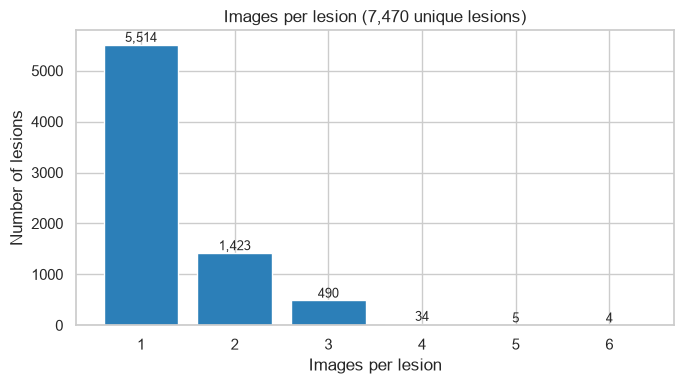

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dist.index.astype(str), dist.values, color="#2c7fb8")
for x, v in zip(dist.index.astype(str), dist.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Images per lesion")
ax.set_ylabel("Number of lesions")
ax.set_title(f"Images per lesion ({n_lesions:,} unique lesions)")
fig.tight_layout()
save_fig(fig, "02_images_per_lesion")
plt.show()

### Consistency within a lesion
All images of the same lesion come from the same patient and the same spot, so `dx`, `age`, `sex` and `localization` should be identical.
`dropna=False` treats a blank age as its own value, so a lesion with one blank and one filled age also counts as inconsistent.

In [17]:
check_cols = ["dx", "dx_type", "age", "sex", "localization"]
nuniq = meta.groupby("lesion_id")[check_cols].nunique(dropna=False)
inconsistent = (nuniq > 1).sum().rename("lesions with >1 distinct value").to_frame()
display(inconsistent)
for col, n in inconsistent.iloc[:, 0].items():
    fact("Lesions", f"Lesions with inconsistent {col} across images", fmt_n(n))
bad = nuniq[(nuniq > 1).any(axis=1)]
if len(bad):
    print("Examples of inconsistent lesions:")
    display(meta[meta["lesion_id"].isin(bad.index[:5])].sort_values("lesion_id"))
else:
    print("No lesion has conflicting values across its images.")

,lesions with >1 distinct value
dx,0
dx_type,0
age,0
sex,0
localization,2


Examples of inconsistent lesions:


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,malignant
1211,HAM_0000871,ISIC_0025964,mel,histo,40.0,female,chest,vidir_modern,True
1212,HAM_0000871,ISIC_0030623,mel,histo,40.0,female,chest,vidir_modern,True
2014,HAM_0000871,ISIC_0026506,mel,histo,40.0,female,trunk,vidir_molemax,True
1247,HAM_0001726,ISIC_0029281,mel,histo,35.0,female,back,vidir_modern,True
1248,HAM_0001726,ISIC_0024367,mel,histo,35.0,female,back,vidir_modern,True
2008,HAM_0001726,ISIC_0024700,mel,histo,35.0,female,trunk,vidir_molemax,True


### Why the train/test split must be done by `lesion_id`
About a quarter of lesions have more than one image, and those images look almost the same (same mole, same patient).
If we split **by image**, one picture of a mole can land in training and another picture of the *same* mole in the test set.
The model then "recognizes" a mole it has already seen instead of truly diagnosing a new one, so the test score looks better
than real-world performance (this is called *data leakage*). Splitting **by `lesion_id`** — all images of a lesion go to the
same side — gives an honest estimate. (Ideally one would split by patient, but HAM10000 has no patient ID.)

## 4. Patient metadata
Age, sex and body site (`localization`) describe *who* the images come from. This matters for fairness and for knowing
which patients a model will work well for. Age is stored in 5-year steps (rounded), which protects patient privacy.

In [18]:
age = meta["age"]
age_steps = sorted(age.dropna().unique())
is_5yr = bool(np.all(np.mod(age.dropna(), 5) == 0))
print(f"Age range: {age.min():.0f}–{age.max():.0f} years; mean {age.mean():.1f}, median {age.median():.0f}")
print(f"Distinct age values: {len(age_steps)} -> {[int(a) for a in age_steps]}")
print("All ages are multiples of 5:", is_5yr)
display(age.value_counts().sort_index().rename("images").to_frame().T)

fact("Patient metadata", "Age range", f"{age.min():.0f}–{age.max():.0f} years")
fact("Patient metadata", "Mean age / median age", f"{age.mean():.1f} / {age.median():.0f} years")
fact("Patient metadata", "Age stored in 5-year steps", "yes" if is_5yr else "no")
fact("Patient metadata", "Most common age", f"{age.mode()[0]:.0f} years ({fmt_n((age == age.mode()[0]).sum())} images)")

Age range: 0–85 years; mean 51.9, median 50
Distinct age values: 18 -> [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85]
All ages are multiples of 5: True


age,0.0,5.0,10.0,15.0,20.0,25.0,30.0,35.0,40.0,45.0,50.0,55.0,60.0,65.0,70.0,75.0,80.0,85.0
images,39,86,41,77,169,247,464,753,985,1299,1187,1009,803,731,756,618,404,290


Saved outputs/figures/03_age_histogram.png


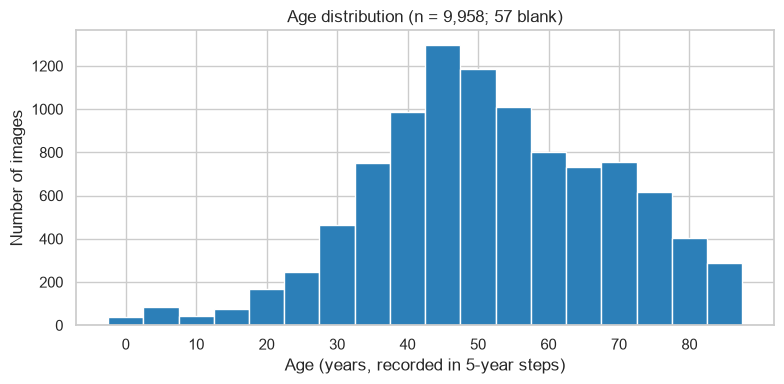

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-2.5, age.max() + 7.5, 5)
ax.hist(age.dropna(), bins=bins, color="#2c7fb8", edgecolor="white")
ax.set_xlabel("Age (years, recorded in 5-year steps)")
ax.set_ylabel("Number of images")
ax.set_title(f"Age distribution (n = {age.notna().sum():,}; {age.isna().sum()} blank)")
ax.set_xticks(np.arange(0, age.max() + 1, 10))
fig.tight_layout()
save_fig(fig, "03_age_histogram")
plt.show()

In [20]:
sex_table = count_table(meta["sex"])
display(sex_table)
for k, row in sex_table.iterrows():
    fact("Patient metadata", f"Sex: {k}", f"{fmt_n(row['count'])} images ({fmt_pct(row['percent'])})")

loc_table = count_table(meta["localization"])
display(loc_table)
for k, row in loc_table.iterrows():
    fact("Patient metadata", f"Localization: {k}", f"{fmt_n(row['count'])} images ({fmt_pct(row['percent'])})")
fact("Patient metadata", "Distinct localization values (incl. 'unknown')", str(meta['localization'].nunique()))

,count,percent
sex,,
male,5406,54.0
female,4552,45.5
unknown,57,0.6


,count,percent
localization,,
back,2192,21.9
lower extremity,2077,20.7
trunk,1404,14.0
upper extremity,1118,11.2
abdomen,1022,10.2
face,745,7.4
chest,407,4.1
foot,319,3.2
unknown,234,2.3


### Source collections
The extra `dataset` column records where each image came from. According to the HAM10000 paper, the `vidir_*` and `vienna_dias`
collections come from the Medical University of Vienna (**Austria**) and `rosendahl` from a skin-cancer practice in Queensland (**Australia**).

In [21]:
if "dataset" in meta.columns:
    COUNTRY = {"vidir_modern": "Austria", "vidir_molemax": "Austria", "vienna_dias": "Austria", "rosendahl": "Australia"}
    src = count_table(meta["dataset"])
    src.insert(0, "country", [COUNTRY.get(k, "?") for k in src.index])
    display(src)
    country = meta["dataset"].map(COUNTRY).fillna("unknown")
    country_table = count_table(country, "country")
    display(country_table)
    for k, row in src.iterrows():
        fact("Patient metadata", f"Source collection {k} ({row['country']})", f"{fmt_n(row['count'])} images ({fmt_pct(row['percent'])})")
    for k, row in country_table.iterrows():
        fact("Patient metadata", f"Images from {k}", f"{fmt_n(row['count'])} ({fmt_pct(row['percent'])})")
    display(pd.crosstab(meta["dx"], meta["dataset"]))
else:
    print("No 'dataset' column in this metadata file.")

,country,count,percent
dataset,,,
vidir_molemax,Austria,3954,39.5
vidir_modern,Austria,3363,33.6
rosendahl,Australia,2259,22.6
vienna_dias,Austria,439,4.4


,count,percent
country,,
Austria,7756,77.4
Australia,2259,22.6


dataset,rosendahl,vidir_modern,vidir_molemax,vienna_dias
dx,,,,
akiec,295,32,0,0
bcc,296,211,2,5
bkl,490,475,124,10
df,30,51,30,4
mel,342,680,24,67
nv,803,1832,3720,350
vasc,3,82,54,3


### Malignant share by age group and by body site
Does the share of cancerous lesions change with age or body site? This shows where the dataset has many vs. few malignant examples.

In [22]:
age_group = pd.cut(meta["age"], bins=[-1, 19, 39, 59, 79, 200],
                   labels=["0–19", "20–39", "40–59", "60–79", "80+"]).cat.add_categories("blank").fillna("blank")
by_age = meta.groupby(age_group, observed=False)["malignant"].agg(images="size", malignant="sum")
by_age["malignant %"] = (100 * by_age["malignant"] / by_age["images"]).round(1)
by_age.index.name = "age group"
display(by_age)
for k, row in by_age.iterrows():
    fact("Patient metadata", f"Malignant share, age {k}", f"{fmt_pct(row['malignant %'])} ({fmt_n(row['malignant'])} of {fmt_n(row['images'])})")

,images,malignant,malignant %
age group,,,
0–19,243,1,0.4
20–39,1633,106,6.5
40–59,4480,527,11.8
60–79,2908,970,33.4
80+,694,348,50.1
blank,57,2,3.5


,images,malignant,malignant %
localization,,,
face,745,318,42.7
scalp,128,47,36.7
ear,56,20,35.7
neck,168,53,31.5
chest,407,127,31.2
upper extremity,1118,324,29.0
back,2192,539,24.6
hand,90,16,17.8
lower extremity,2077,315,15.2


Saved outputs/figures/04_malignant_share_by_site.png


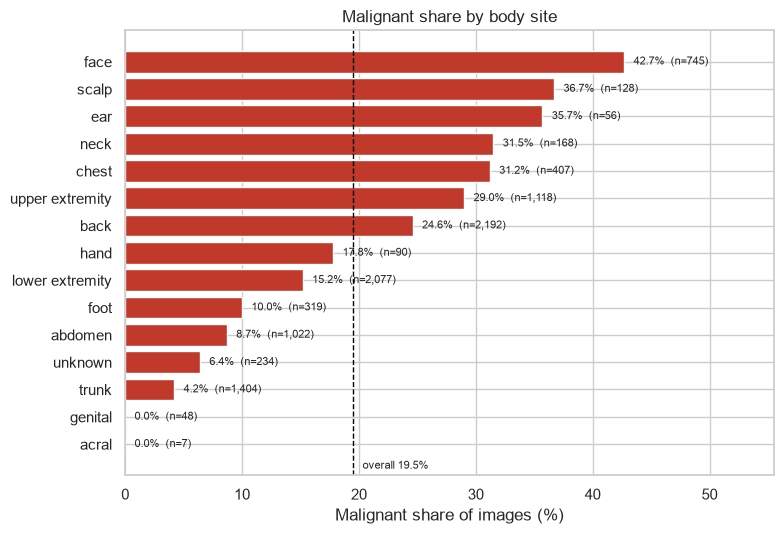

In [23]:
by_loc = meta.groupby("localization")["malignant"].agg(images="size", malignant="sum")
by_loc["malignant %"] = (100 * by_loc["malignant"] / by_loc["images"]).round(1)
by_loc = by_loc.sort_values("malignant %", ascending=False)
display(by_loc)
for k, row in by_loc.iterrows():
    fact("Patient metadata", f"Malignant share, site {k}", f"{fmt_pct(row['malignant %'])} ({fmt_n(row['malignant'])} of {fmt_n(row['images'])})")

plot = by_loc.sort_values("malignant %")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(plot.index, plot["malignant %"], color="#c0392b")
for y, (p, n) in enumerate(zip(plot["malignant %"], plot["images"])):
    ax.text(p + 0.8, y, f"{p:.1f}%  (n={n:,})", va="center", fontsize=8)
ax.axvline(malig_pct, color="black", ls="--", lw=1)
ax.text(malig_pct + 0.8, -0.9, f"overall {malig_pct:.1f}%", fontsize=8)
ax.set_xlabel("Malignant share of images (%)")
ax.set_title("Malignant share by body site")
ax.set_xlim(0, plot["malignant %"].max() * 1.3)
fig.tight_layout()
save_fig(fig, "04_malignant_share_by_site")
plt.show()

## 5. Image files
Now we check the actual image files: does every `image_id` in the table have exactly one file (and no extra files)?
Can every file be opened, or are some corrupt? Are all images the same size and colour mode? And are any two files byte-for-byte
identical (MD5 hash)? If the image folders are not available, this section is skipped and says so.

In [24]:
if not IMAGES_AVAILABLE:
    display(Markdown("**Section 5 skipped: image folders not found in `data/`.** All other sections are complete."))
    image_files = {}
else:
    all_files = [p for d in IMAGE_DIRS for p in d.iterdir() if p.is_file() and not p.name.startswith(".")]
    print("Files per folder:", {d.name: sum(1 for p in all_files if p.parent == d) for d in IMAGE_DIRS})
    print("File extensions:", pd.Series([p.suffix.lower() for p in all_files]).value_counts().to_dict())
    by_stem = pd.Series([p.stem for p in all_files]).value_counts()
    image_files = {p.stem: p for p in all_files}

    ids = set(meta["image_id"])
    missing_files = sorted(ids - set(by_stem.index))
    extra_files = sorted(set(by_stem.index) - ids)
    multi_files = sorted(by_stem[by_stem > 1].index)
    print(f"Image files found: {len(all_files):,}")
    print(f"image_ids without a file: {len(missing_files):,}", missing_files[:20])
    print(f"Files without a metadata row (extra): {len(extra_files):,}", extra_files[:20])
    print(f"image_ids with more than one file: {len(multi_files):,}", multi_files[:20])
    print("Every image_id has exactly one file:", not missing_files and not multi_files)

    fact("Image files", "Image files found", fmt_n(len(all_files)))
    fact("Image files", "image_ids without a file", fmt_n(len(missing_files)))
    fact("Image files", "Extra files without a metadata row", fmt_n(len(extra_files)))
    fact("Image files", "image_ids with more than one file", fmt_n(len(multi_files)))

Files per folder: {'HAM10000_images_part_1': 5000, 'HAM10000_images_part_2': 5015}
File extensions: {'.jpg': 10015}
Image files found: 10,015
image_ids without a file: 0 []
Files without a metadata row (extra): 0 []
image_ids with more than one file: 0 []
Every image_id has exactly one file: True


Open every image fully (decode all pixels) to find corrupt files, record size and colour mode, and compute an MD5 hash of the
file bytes. This reads all ~10,000 files, so it takes a minute or two.

In [25]:
if IMAGES_AVAILABLE:
    records = []
    for image_id in meta["image_id"]:
        path = image_files.get(image_id)
        if path is None:
            continue
        raw = path.read_bytes()
        rec = {"image_id": image_id, "file_bytes": len(raw), "md5": hashlib.md5(raw).hexdigest()}
        try:
            with Image.open(io.BytesIO(raw)) as im:
                im.load()
                rec.update(width=im.width, height=im.height, mode=im.mode, format=im.format, ok=True, error="")
        except Exception as e:  # corrupt / truncated file
            rec.update(width=np.nan, height=np.nan, mode="", format="", ok=False, error=repr(e))
        records.append(rec)
    img = pd.DataFrame(records)

    n_corrupt = int((~img["ok"]).sum())
    print(f"Images opened: {len(img):,}   corrupt: {n_corrupt}")
    if n_corrupt:
        display(img.loc[~img["ok"], ["image_id", "error"]])
    sizes = img.groupby(["width", "height", "mode", "format"]).size().rename("images").reset_index()
    display(sizes)
    all_600x450_rgb = bool(((img["width"] == 600) & (img["height"] == 450) & (img["mode"] == "RGB")).all())
    print("All images are 600 × 450 RGB:", all_600x450_rgb)
    print(f"File size: {img['file_bytes'].min()/1024:.0f}–{img['file_bytes'].max()/1024:.0f} KB, "
          f"total {img['file_bytes'].sum()/1024**3:.2f} GB")

    fact("Image files", "Images opened with Pillow", fmt_n(len(img)))
    fact("Image files", "Corrupt / unreadable images", fmt_n(n_corrupt))
    fact("Image files", "Image size / mode / format",
         "; ".join(f"{int(r.width)} × {int(r.height)} {r.mode} {r.format}: {r.images:,}" for r in sizes.itertuples()))
    fact("Image files", "All images 600 × 450 RGB", "yes" if all_600x450_rgb else "no")
    fact("Image files", "Total image data", f"{img['file_bytes'].sum()/1024**3:.2f} GB")

Images opened: 10,015   corrupt: 0


,width,height,mode,format,images
0,600,450,RGB,JPEG,10015


All images are 600 × 450 RGB: True
File size: 83–479 KB, total 2.58 GB


In [26]:
if IMAGES_AVAILABLE:
    dup_mask = img["md5"].duplicated(keep=False)
    dup_groups = img[dup_mask].groupby("md5")["image_id"].apply(list)
    n_dup_files = int(img["md5"].duplicated().sum())
    print(f"Distinct MD5 hashes: {img['md5'].nunique():,}")
    print(f"Exact duplicate image files (extra copies): {n_dup_files}")
    if len(dup_groups):
        dup_detail = meta.set_index("image_id").loc[[i for g in dup_groups for i in g], ["lesion_id", "dx"]]
        display(dup_detail)
    dup_same_lesion = int(sum(meta.set_index("image_id").loc[g, "lesion_id"].nunique() == 1 for g in dup_groups))
    print(f"Duplicate groups: {len(dup_groups)}, of which within the same lesion_id: {dup_same_lesion}")
    fact("Image files", "Exact duplicate image files (identical MD5)", fmt_n(n_dup_files))
    if len(dup_groups):
        fact("Image files", "Duplicate pairs", "; ".join(" = ".join(g) for g in dup_groups))
        fact("Image files", "Duplicate groups within the same lesion_id", f"{dup_same_lesion} of {len(dup_groups)}")
    img.to_csv(OUT_DIR / "ham10000_image_checks.csv", index=False)
    print("Saved", (OUT_DIR / "ham10000_image_checks.csv").relative_to(PROJECT_DIR))
else:
    n_dup_files = None
    dup_groups, dup_same_lesion = [], 0

Distinct MD5 hashes: 10,013
Exact duplicate image files (extra copies): 2


,lesion_id,dx
image_id,,
ISIC_0029861,HAM_0002300,nv
ISIC_0024366,HAM_0002300,nv
ISIC_0029938,HAM_0001895,nv
ISIC_0024777,HAM_0001895,nv


Duplicate groups: 2, of which within the same lesion_id: 2
Saved outputs/ham10000_image_checks.csv


### Sample images
Three random images per class (fixed random seed, so the figure is reproducible).

Saved outputs/figures/05_sample_images.png


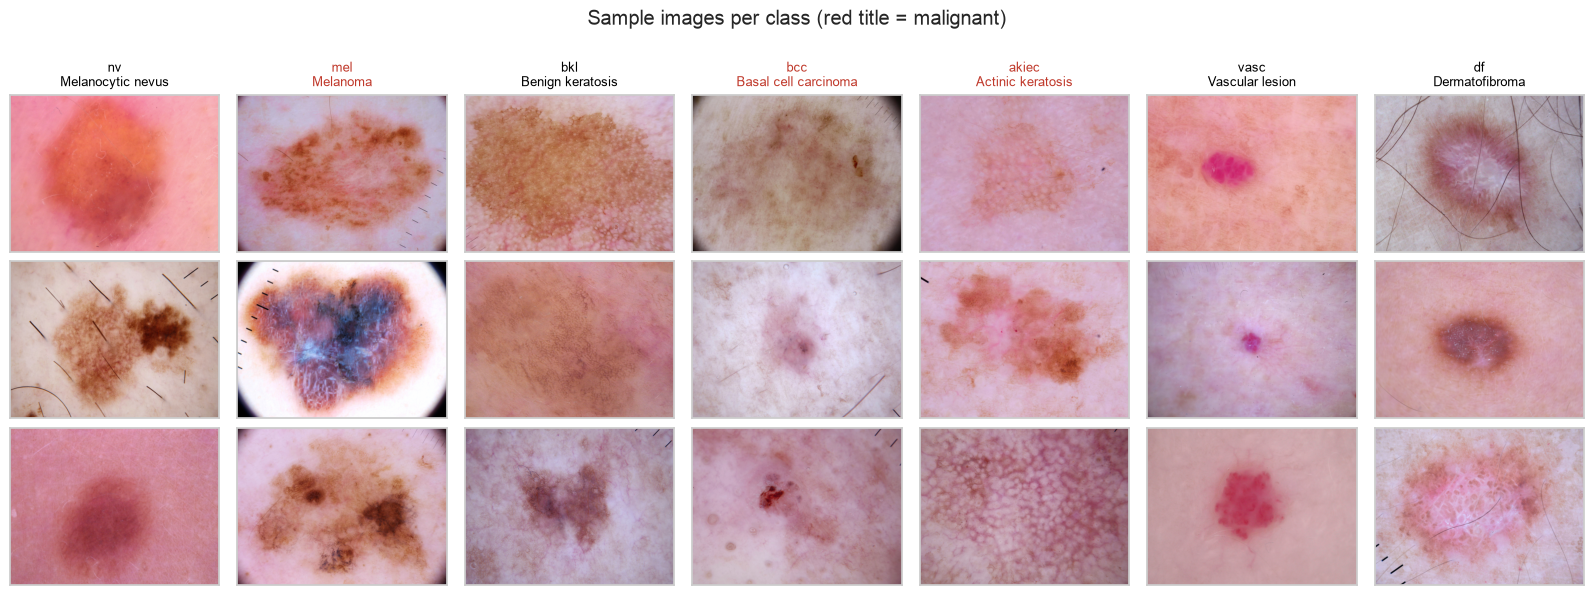

In [27]:
if IMAGES_AVAILABLE:
    classes = list(dx_table.sort_values("count", ascending=False).index)
    n_per = 3
    fig, axes = plt.subplots(n_per, len(classes), figsize=(2.3 * len(classes), 2.0 * n_per))
    for j, k in enumerate(classes):
        sample = meta[meta["dx"] == k].sample(n_per, random_state=42)
        for i, image_id in enumerate(sample["image_id"]):
            ax = axes[i, j]
            with Image.open(image_files[image_id]) as im:
                ax.imshow(im)
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title(f"{k}\n{DX_NAMES[k].split(' /')[0]}", fontsize=9,
                             color="#c0392b" if k in MALIGNANT else "black")
    fig.suptitle("Sample images per class (red title = malignant)", y=1.0)
    fig.tight_layout()
    save_fig(fig, "05_sample_images")
    plt.show()

## 6. Summary
### One-row summary table
The headline numbers in one row, saved to `outputs/ham10000_summary.csv`.

In [28]:
summary = pd.DataFrame([{
    "rows": n_rows,
    "columns": n_cols,
    "blank_cells": total_blank,
    "blank_cells_pct": round(pct(total_blank, total_cells), 2),
    "hidden_missing_cells": hidden_missing_cells,
    "age_blank": age_blank,
    "sex_unknown": sex_unknown,
    "localization_unknown": loc_unknown,
    "duplicate_rows": dup_rows,
    "duplicate_image_ids": dup_image_ids,
    "duplicate_image_files": n_dup_files,
    "unique_lesions": n_lesions,
    "malignant_images": n_malig,
    "malignant_pct": round(malig_pct, 1),
}])
summary.to_csv(OUT_DIR / "ham10000_summary.csv", index=False)
print("Saved", (OUT_DIR / "ham10000_summary.csv").relative_to(PROJECT_DIR))
summary.T.rename(columns={0: "value"})

Saved outputs/ham10000_summary.csv


,value
rows,10015.00
columns,8.00
blank_cells,57.00
blank_cells_pct,0.07
hidden_missing_cells,291.00
age_blank,57.00
sex_unknown,57.00
localization_unknown,234.00
duplicate_rows,0.00
duplicate_image_ids,0.00


### Comparison with reference values
Each value from published descriptions of the dataset is compared with the value computed above. ✅ = matches, ❌ = differs.

In [29]:
dxc = meta["dx"].value_counts()
nv_pct, df_pct = pct(dxc["nv"], n_rows), pct(dxc["df"], n_rows)
n_histo = int((meta["dx_type"] == "histo").sum())

ref = [
    ("Images", 10015, n_rows, n_rows == 10015),
    ("Metadata columns", 7, n_cols, n_cols == 7),
    ("Unique lesions", 7470, n_lesions, n_lesions == 7470),
]
for k, v in {"nv": 6705, "mel": 1113, "bkl": 1099, "bcc": 514, "akiec": 327, "vasc": 142, "df": 115}.items():
    ref.append((f"dx count: {k}", v, int(dxc.get(k, 0)), int(dxc.get(k, 0)) == v))
ref += [
    ("nv share ≈ 67%", "≈ 67%", fmt_pct(nv_pct), round(nv_pct) == 67),
    ("df share ≈ 1.1%", "≈ 1.1%", fmt_pct(df_pct), round(df_pct, 1) == 1.1),
    ("Histo-confirmed images", 5340, n_histo, n_histo == 5340),
    ("Histo-confirmed is more than half", "> 50%", fmt_pct(pct(n_histo, n_rows)), n_histo > n_rows / 2),
    ("Age blank", 57, age_blank, age_blank == 57),
    ("Sex 'unknown'", 57, sex_unknown, sex_unknown == 57),
    ("Localization 'unknown'", 234, loc_unknown, loc_unknown == 234),
]
if IMAGES_AVAILABLE:
    ref += [
        ("All images 600 × 450", "yes", "yes" if all_600x450_rgb else "no", all_600x450_rgb),
        ("Duplicate images", 0, n_dup_files, n_dup_files == 0),
    ]
else:
    ref += [("All images 600 × 450", "yes", "not checked (no images)", False),
            ("Duplicate images", 0, "not checked (no images)", False)]

comparison = pd.DataFrame(ref, columns=["item", "reference", "computed", "match"])
comparison["status"] = np.where(comparison["match"], "✅", "❌")
comparison["reference"] = comparison["reference"].map(lambda v: f"{v:,}" if isinstance(v, int) else v)
comparison["computed"] = comparison["computed"].map(lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else v)
comparison = comparison.drop(columns="match")
comparison.to_csv(OUT_DIR / "ham10000_reference_comparison.csv", index=False)
display(comparison)
differs = comparison[comparison["status"] == "❌"]
print(f"{len(comparison) - len(differs)} of {len(comparison)} reference values match.")
if len(differs):
    print("Differences:", "; ".join(f"{r.item}: reference {r.reference}, computed {r.computed}" for r in differs.itertuples()))

,item,reference,computed,status
0,Images,"10,015","10,015",✅
1,Metadata columns,7,8,❌
2,Unique lesions,"7,470","7,470",✅
3,dx count: nv,"6,705","6,705",✅
4,dx count: mel,"1,113","1,113",✅
5,dx count: bkl,"1,099","1,099",✅
6,dx count: bcc,514,514,✅
7,dx count: akiec,327,327,✅
8,dx count: vasc,142,142,✅
9,dx count: df,115,115,✅


17 of 19 reference values match.
Differences: Metadata columns: reference 7, computed 8; Duplicate images: reference 0, computed 2


### Conclusion: data-quality issues and what they mean for modeling
The text below is generated from the computed numbers, so it always matches the results above.

In [30]:
top = dx_table.sort_values("count", ascending=False)
au = meta["dataset"].map(COUNTRY) if "dataset" in meta.columns else None
au_line = (f" ({fmt_n((au == 'Austria').sum())} images / {fmt_pct(pct((au == 'Austria').sum(), n_rows))} from Austria, "
           f"{fmt_n((au == 'Australia').sum())} / {fmt_pct(pct((au == 'Australia').sum(), n_rows))} from Australia)") if au is not None else ""
n_incons = int((nuniq > 1).any(axis=1).sum())
incons_cols = [c for c, n in (nuniq > 1).sum().items() if n]
incons_line = ("every lesion has consistent values across its images" if n_incons == 0 else
               f"only {n_incons} lesion(s) have conflicting values across their images (in: {', '.join(incons_cols)})")
dup_note = ""
if IMAGES_AVAILABLE and len(dup_groups):
    dup_note = (f" The {n_dup_files} duplicate file(s) ({'; '.join(' = '.join(g) for g in dup_groups)}) "
                f"{'all belong to the same lesion as their twin' if dup_same_lesion == len(dup_groups) else 'include pairs across different lesions'}, "
                f"so a lesion-level split keeps each pair on one side, but they slightly over-weight those lesions.")
img_line = (f"All {fmt_n(len(img))} image files exist, open without errors ({n_corrupt} corrupt), are "
            f"{'all' if all_600x450_rgb else 'not all'} 600 × 450 RGB, and {n_dup_files} are exact byte-level duplicates."
            if IMAGES_AVAILABLE else "Image files were not available, so file-level checks were skipped.")

conclusion = f"""
**Overall:** the metadata table is technically clean — {fmt_n(n_rows)} rows, {dup_rows} duplicate rows, {dup_image_ids} duplicate image IDs,
only {total_blank} blank cells ({pct(total_blank, total_cells):.2f}% of all cells), and {incons_line}.
{img_line}{dup_note} The real issues are about *what* the data represents:

1. **Strong class imbalance.** `nv` (benign moles) makes up {fmt_pct(top.loc['nv','percent'])} of images, while `df` is only
   {fmt_pct(top.loc['df','percent'])} ({imbalance_ratio:.0f} : 1). Malignant lesions are {fmt_pct(malig_pct)} of images.
   A model that always says "nevus" would already be ~{top.loc['nv','percent']:.0f}% accurate, so accuracy is misleading — use per-class
   recall/sensitivity (especially for melanoma), balanced accuracy or F1, and consider class weights or resampling.
2. **Lesion-level split required.** {fmt_n(n_rows)} images show only {fmt_n(n_lesions)} unique lesions; {fmt_n(multi)} lesions
   ({fmt_pct(pct(multi, n_lesions))}) have 2+ images, covering {fmt_pct(pct(imgs_in_multi, n_rows))} of all images. Train/validation/test
   must be split by `lesion_id` to avoid leakage. There is no patient ID, so leakage across different lesions of the same patient cannot be ruled out.
3. **Unknown values.** Age is blank for {age_blank} images, sex is "unknown" for {sex_unknown}, localization is "unknown" for {loc_unknown}
   ({fmt_n(any_unknown.sum())} images / {fmt_pct(pct(any_unknown.sum(), n_rows))} have at least one). These are hidden as text, not blanks,
   so they must be handled explicitly if metadata is used as model input. {age_zero} images have age 0, which may be genuine (infants) or a placeholder.
4. **Label certainty varies.** {fmt_pct(pct(n_histo, n_rows))} of images are histopathology-confirmed (all malignant classes: {fmt_pct(histo_malig)}),
   but many benign moles are confirmed only by follow-up or consensus, so some labels are less certain.
5. **Limited population.** All patients come from two places — Austria (Vienna) and Australia (Queensland){au_line}. The patients are
   likely mostly fair-skinned, and the images come from a few specific dermatoscopes and clinics. A model trained here may not
   generalize to darker skin types, other devices or other countries; external validation is needed before any clinical use.
"""
display(Markdown(conclusion))


**Overall:** the metadata table is technically clean — 10,015 rows, 0 duplicate rows, 0 duplicate image IDs,
only 57 blank cells (0.07% of all cells), and only 2 lesion(s) have conflicting values across their images (in: localization).
All 10,015 image files exist, open without errors (0 corrupt), are all 600 × 450 RGB, and 2 are exact byte-level duplicates. The 2 duplicate file(s) (ISIC_0029861 = ISIC_0024366; ISIC_0029938 = ISIC_0024777) all belong to the same lesion as their twin, so a lesion-level split keeps each pair on one side, but they slightly over-weight those lesions. The real issues are about *what* the data represents:

1. **Strong class imbalance.** `nv` (benign moles) makes up 66.9% of images, while `df` is only
   1.1% (58 : 1). Malignant lesions are 19.5% of images.
   A model that always says "nevus" would already be ~67% accurate, so accuracy is misleading — use per-class
   recall/sensitivity (especially for melanoma), balanced accuracy or F1, and consider class weights or resampling.
2. **Lesion-level split required.** 10,015 images show only 7,470 unique lesions; 1,956 lesions
   (26.2%) have 2+ images, covering 44.9% of all images. Train/validation/test
   must be split by `lesion_id` to avoid leakage. There is no patient ID, so leakage across different lesions of the same patient cannot be ruled out.
3. **Unknown values.** Age is blank for 57 images, sex is "unknown" for 57, localization is "unknown" for 234
   (254 images / 2.5% have at least one). These are hidden as text, not blanks,
   so they must be handled explicitly if metadata is used as model input. 39 images have age 0, which may be genuine (infants) or a placeholder.
4. **Label certainty varies.** 53.3% of images are histopathology-confirmed (all malignant classes: 100.0%),
   but many benign moles are confirmed only by follow-up or consensus, so some labels are less certain.
5. **Limited population.** All patients come from two places — Austria (Vienna) and Australia (Queensland) (7,756 images / 77.4% from Austria, 2,259 / 22.6% from Australia). The patients are
   likely mostly fair-skinned, and the images come from a few specific dermatoscopes and clinics. A model trained here may not
   generalize to darker skin types, other devices or other countries; external validation is needed before any clinical use.


### Facts file
Every key number collected above, grouped by section, exported as a plain list to `outputs/ham10000_facts.md` for writing the paper.

In [31]:
dq = [
    f"Class imbalance: largest class nv is {fmt_pct(top.loc['nv','percent'])}, smallest df is {fmt_pct(top.loc['df','percent'])} ({imbalance_ratio:.1f} : 1)",
    f"Malignant share: {fmt_pct(malig_pct)} ({fmt_n(n_malig)} images)",
    f"Lesion-level split needed: {fmt_n(multi)} lesions have 2+ images ({fmt_pct(pct(imgs_in_multi, n_rows))} of images)",
    f"Unknown values: age blank {age_blank}, sex unknown {sex_unknown}, localization unknown {loc_unknown}",
    f"Images with at least one unknown: {fmt_n(any_unknown.sum())} ({fmt_pct(pct(any_unknown.sum(), n_rows))})",
    "Patient origin: Austria (Vienna) and Australia (Queensland) only",
    f"Lesions with conflicting values across images: {n_incons}" + (f" (in: {', '.join(incons_cols)})" if incons_cols else ""),
    f"Age recorded as 0: {age_zero} images (genuine infants or placeholder - unclear)",
    f"Exact duplicate image files: {n_dup_files}" + (f" (same lesion: {dup_same_lesion} of {len(dup_groups)} pairs)" if len(dup_groups) else ""),
    "No patient ID in the metadata (leakage across lesions of one patient cannot be checked)",
    f"Reference values matching: {len(comparison) - len(differs)} of {len(comparison)}",
] + [f"Differs from reference: {r.item} (reference {r.reference}, computed {r.computed})" for r in differs.itertuples()]
FACTS["Data-quality issues"] = dq

SECTION_ORDER = ["Structure", "Labels", "Lesions", "Patient metadata", "Image files", "Data-quality issues"]
lines = ["# HAM10000 — key facts", "",
         "Computed from the complete dataset (Tschandl et al., 2018; https://doi.org/10.7910/DVN/DBW86T) by `ham10000_quality.ipynb`.",
         "Percentages are of all 10,015 images unless stated otherwise.", ""]
for sec in SECTION_ORDER:
    if sec not in FACTS:
        lines += [f"## {sec}", "", "- Not checked (data not available)", ""]
        continue
    lines += [f"## {sec}", ""] + [f"- {item}" for item in FACTS[sec]] + [""]
facts_text = "\n".join(lines)
(OUT_DIR / "ham10000_facts.md").write_text(facts_text, encoding="utf-8")
print("Saved", (OUT_DIR / "ham10000_facts.md").relative_to(PROJECT_DIR))
print(f"{sum(len(v) for v in FACTS.values())} facts written.")
print()
print(facts_text)

Saved outputs/ham10000_facts.md
124 facts written.

# HAM10000 — key facts

Computed from the complete dataset (Tschandl et al., 2018; https://doi.org/10.7910/DVN/DBW86T) by `ham10000_quality.ipynb`.
Percentages are of all 10,015 images unless stated otherwise.

## Structure

- Images (metadata rows): 10,015
- Metadata columns: 8 (lesion_id, image_id, dx, dx_type, age, sex, localization, dataset)
- Extra column(s) not in the 7 documented ones: dataset
- Total cells: 80,120
- Blank cells (total): 57 (0.07% of all cells)
- Blank cells in age: 57 images (0.6%)
- Age missing (blank): 57 images (0.6%)
- Sex 'unknown': 57 images (0.6%)
- Localization 'unknown': 234 images (2.3%)
- Empty strings: 0
- Impossible ages (<0 or >120): 0
- Age recorded as 0: 39 images
- Hidden-missing cells (unknown/empty/impossible): 291
- Images with at least one unknown (age, sex or localization): 254 (2.5%)
- Exact duplicate rows: 0
- Duplicate image_ids: 0

## Labels

- Melanocytic nevus (nv): 6,705 images (66